# 7.1.2 - Model: Random Forest (lemmatized variant)

**Training and evaluation of the Random Forest classifier on the lemmatized variant of the TF-IDF data.**

## Theoretical background

Random Forest is an ensemble method - instead of training a single tree (as in `6.1`), it trains many independent Decision Tree models and combines their predictions into one final decision in order to obtain a more stable and accurate classifier.

Each tree in the forest is built in a slightly different way than a standard Decision Tree:
- Bootstrap sampling (bagging) - each tree is trained on its own random sample of the TRAIN set, drawn with replacement (the same example may appear multiple times, while some examples may be completely omitted)
- Random subset of features per split - at each node split, the tree does not consider all features (as a standard Decision Tree does), but only a randomly selected subset (controlled by the `max_features` parameter)
- Multiple trees – the number of trees in the forest is determined by the `n_estimators` parameter (a larger number of trees generally produces more stable results, but increases training time).

The final prediction of the entire forest is the majority vote of all individual trees.

Why this helps:
- An individual tree is unstable - a small change in the training data can produce a completely different tree, and it is prone to overfitting
- By averaging across many different, weakly dependent trees, the errors of individual trees cancel each other out, and the forest as a whole generalizes better to new data

Cost:
- We lose the direct interpretability of an individual tree (now we have many trees instead of one, so we cannot simply "follow" a single sequence of decisions)
- We retain some degree of interpretability through `feature_importances_` (averaged across all trees in the forest, instead of coming from a single tree as in `6.1`)

## Note about the name `max_features`

`max_features` here is not the same parameter as `max_features` from `3_vectorization.ipynb` (there it controlled the size of the entire TF-IDF vocabulary).

`max_features` here controls how many features are randomly considered at each individual node split within a single tree.

## Processing flow:

1. We load the previously prepared lemmatized TF-IDF data using the `load_variant()` function

2. We create a `RandomForestClassifier` and define the values of the hyperparameters `n_estimators`, `max_depth`, `max_features` and `min_samples_leaf` that will be examined by `GridSearchCV`

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - examines all combinations of hyperparameters from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the combination of hyperparameters that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used for the first time on the TEST set
        - accuracy, precision, recall and F1 are calculated, and a confusion matrix is created
    4. Saving the results

4. We analyze `feature_importances_` (averaged across all trees in the forest) to see which terms contribute the most to the decisions


In [1]:
import sys
sys.path.append("..")

import numpy as np
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.ensemble import RandomForestClassifier

## Data Loading

We load the lemmatized variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lemmatized")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 66834)
Test:  (9917, 66834)


## Model and Hyperparameters

Hyperparameters: `n_estimators`, `max_depth`, `max_features` and `min_samples_leaf`

- `n_estimators` - number of trees in the forest
  - More trees → more stable, reliable results (averaging across more "votes")
  - But also slower training - each additional tree increases training time

- `max_depth` - maximum depth of each individual tree in the forest (`None` → no explicit depth limit)

- `max_features` - how many features are randomly considered at each split
  - `"sqrt"` - considers √66.834 ≈ 258 features per split
  - `"log2"` - considers log₂(66.834) ≈ 17 features per split
  - Fewer features per split means more diverse trees (a lower chance that two trees make the same split), which can improve the ensemble effect

- `min_samples_leaf` - minimum number of samples that a leaf must contain for a split to be allowed
  - A higher value prevents the creation of very small leaves and thus further regularizes the model


In [ ]:
model = RandomForestClassifier(random_state=1)

param_grid = {
    "n_estimators": [1000, 1500, 2000, 2500, 3000],
    "max_depth": [300, 400, 500, 600],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 2, 3],
}

## Training and Evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `n_estimators`, `max_depth`, `max_features` and `min_samples_leaf` using 5-fold GridSearchCV on the training set, selects the combination with the best F1 score, then trains the best model on the entire training set and evaluates it on the test set.

The results are saved as the model, metrics and confusion matrix.

Duration:
- Decision Tree (`6.2`) took several minutes for dozens of hyperparameter combinations (grid × 5-fold).
- Random Forest builds a larger number of trees FOR EACH combination, instead of just one
- Although each individual tree is cheaper to build here (it considers only a subset of features at each split, rather than all of them), the total time will be significantly longer.


========== random_forest (lem) ==========
Best parameters: {'max_depth': 400, 'max_features': 'log2', 'min_samples_leaf': 2, 'n_estimators': 1500}
GridSearchCV time: 54821.2s

Accuracy  : 0.8767
Precision : 0.8593
Recall    : 0.9019
F1        : 0.8801


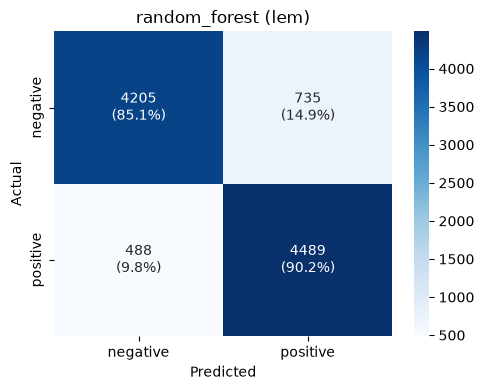


Saved:
  ..\models\random_forest_lem.joblib
  ..\results\metrics\random_forest_lem.json
  ..\results\figures\random_forest_lem_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="random_forest",
    variant="lem",
)

## Most Influential Terms (Feature Importance)

`feature_importances_` represents a measure of feature importance.

The value shows how much a particular term contributed to reducing "impurity" across all splits (same as in `6.2` - `feature_importances_` has no sign).

The difference compared to `6.2`: here, the value is averaged across all trees in the forest; it does not come from a single tree.

We expect the ensemble to "discover" a larger number of useful terms than an individual tree (for a single tree, only a small portion of the vocabulary was used - with hundreds of trees and a random subset of features at each split, it is likely that significantly more terms will receive non-zero importance).

A higher value means that the feature made a greater contribution to reducing impurity during splits in the Random Forest trees.

Feature importance does not show the direction of the effect, meaning it does not indicate whether a term contributes to positive or negative sentiment. Therefore, here we get a single ranking of the most important terms.

We load the saved model and vectorizer back from disk in order to associate the `feature_importances_` values with the specific terms.


In [5]:
best_model = joblib.load("../models/random_forest_lem.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_lem.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
importances = best_model.feature_importances_

top_idx = np.argsort(importances)[-20:][::-1]

print("Top 20 most influential terms:")
for idx in top_idx:
    print(f"  {feature_names[idx]:30s}  {importances[idx]:.4f}")

n_zero_importance = np.sum(importances == 0)
print(f"\nNumber of terms that the forest never used for splitting: {n_zero_importance} out of {len(importances)} ({n_zero_importance / len(importances):.1%})")

Top 20 most influential terms:
  bad                             0.0114
  waste                           0.0060
  great                           0.0055
  bad movie                       0.0045
  awful                           0.0041
  terrible                        0.0037
  not even                        0.0036
  no                              0.0036
  waste time                      0.0032
  love                            0.0031
  not                             0.0030
  wonderful                       0.0030
  excellent                       0.0029
  nothing                         0.0028
  best                            0.0027
  one best                        0.0026
  poor                            0.0026
  horrible                        0.0026
  stupid                          0.0025
  minute                          0.0024

Number of terms that the forest never used for splitting: 3880 out of 66834 (5.8%)


## Conclusions

- Best `max_depth`: 400, `max_features`: log2, `min_samples_leaf`: 2 and `n_estimators`: 1500

- Results:
  - Accuracy  : 0.8767
  - Precision : 0.8593
  - Recall    : 0.9019
  - F1        : 0.8801

- `feature_importances_` shows that the Random Forest used a large portion of the TF-IDF vocabulary — only 5.8% of the terms (3800 out of 66682) were never used for splitting

- The most influential terms match what would be expected (bad, waste, great, awfull,...)

- Interestingly, the log2 limitation on the number of features was selected, which increases the diversity of the trees and contributes to the ensemble effect

- Compared to a single Decision Tree, using a larger number of trees enables a more stable model and reduces the problem of overfitting, because the final decision is based on a combination of predictions from a large number of different trees
